# Investigate a Dataset: TMDb Movie Data

## Introduction

This project explores the **TMDb (The Movie Database) movie dataset**, which contains information about **10,878 movies** released between 1960 and 2015. Each record includes attributes such as budget, revenue, runtime, genres, popularity, vote average, cast, and director.

The dataset was curated for the Udacity Data Analyst Nanodegree and includes inflation-adjusted budget and revenue figures (`budget_adj`, `revenue_adj`).

### Research Questions

1. **Which genres are most popular from year to year?** — How have genre preferences shifted across decades?
2. **What properties are associated with movies that have high revenues?** — Do budget, runtime, vote average, or popularity correlate with revenue?
3. **How has the movie industry evolved over time?** — What are the trends in spending, earnings, and volume of releases?

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style('whitegrid')
sns.set_palette('deep')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

### Helper Functions

The `format_plot` function is reused throughout the notebook to ensure every plot has a title and labeled axes.

In [2]:
def format_plot(ax, title, xlabel, ylabel, legend=False):
    """Apply consistent formatting to a matplotlib Axes.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    title : str
    xlabel : str
    ylabel : str
    legend : bool, optional  – show legend if True
    """
    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    if legend:
        ax.legend(fontsize=10, frameon=True)
    ax.tick_params(labelsize=10)

## Data Wrangling

### Load the data

In [3]:
df = pd.read_csv('/Users/leo/Documents/tmdb-movies.csv')
print(f'Shape: {df.shape}')
df.head(3)

Shape: (10866, 21)


,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,overview,runtime,genres,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj
0,135397,tt0369610,32.985763,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,...,Twenty-two years after the events of Jurassic ...,124,Action|Adventure|Science Fiction|Thriller,Universal Studios|Amblin Entertainment|Legenda...,6/9/15,5562,6.5,2015,1.379999e+08,1.392446e+09
1,76341,tt1392190,28.419936,150000000,378436354,Mad Max: Fury Road,Tom Hardy|Charlize Theron|Hugh Keays-Byrne|Nic...,http://www.madmaxmovie.com/,George Miller,What a Lovely Day.,...,An apocalyptic story set in the furthest reach...,120,Action|Adventure|Science Fiction|Thriller,Village Roadshow Pictures|Kennedy Miller Produ...,5/13/15,6185,7.1,2015,1.379999e+08,3.481613e+08
2,262500,tt2908446,13.112507,110000000,295238201,Insurgent,Shailene Woodley|Theo James|Kate Winslet|Ansel...,http://www.thedivergentseries.movie/#insurgent,Robert Schwentke,One Choice Can Destroy You,...,Beatrice Prior must confront her inner demons ...,119,Adventure|Science Fiction|Thriller,Summit Entertainment|Mandeville Films|Red Wago...,3/18/15,2480,6.3,2015,1.012000e+08,2.716190e+08


### Inspect data types, missing values, and duplicates

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10866 entries, 0 to 10865
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    10866 non-null  int64  
 1   imdb_id               10856 non-null  str    
 2   popularity            10866 non-null  float64
 3   budget                10866 non-null  int64  
 4   revenue               10866 non-null  int64  
 5   original_title        10866 non-null  str    
 6   cast                  10790 non-null  str    
 7   homepage              2936 non-null   str    
 8   director              10822 non-null  str    
 9   tagline               8042 non-null   str    
 10  keywords              9373 non-null   str    
 11  overview              10862 non-null  str    
 12  runtime               10866 non-null  int64  
 13  genres                10843 non-null  str    
 14  production_companies  9836 non-null   str    
 15  release_date          10866 no

In [5]:
# Missing values per column
df.isnull().sum()[df.isnull().sum() > 0]

imdb_id                   10
cast                      76
homepage                7930
director                  44
tagline                 2824
keywords                1493
overview                   4
genres                    23
production_companies    1030
dtype: int64

In [6]:
# Duplicate rows
n_dup = df.duplicated().sum()
print(f'Duplicate rows: {n_dup}')

Duplicate rows: 1


### Clean the data

In [7]:
# 1. Drop duplicate rows
df.drop_duplicates(inplace=True)

# 2. Replace 0 budget / revenue with NaN (0 means missing, not free)
for col in ['budget', 'revenue', 'budget_adj', 'revenue_adj']:
    df[col] = df[col].replace(0, np.nan)

# 3. Parse pipe-separated genres into Python lists
df['genre_list'] = df['genres'].fillna('').str.split('|')

# 4. Create a decade column
df['decade'] = (df['release_year'] // 10) * 10

# 5. Convert release_date to datetime (errors coerce bad dates to NaT)
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

print(f'Clean shape: {df.shape}')
df[['original_title', 'budget', 'revenue', 'genre_list', 'decade']].head()

Clean shape: (10865, 23)


/var/folders/8k/rsg3bc7s5qd3v07_19wz50rc0000gn/T/ipykernel_56855/3242082995.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')


,original_title,budget,revenue,genre_list,decade
0,Jurassic World,150000000.0,1.513529e+09,"[Action, Adventure, Science Fiction, Thriller]",2010
1,Mad Max: Fury Road,150000000.0,3.784364e+08,"[Action, Adventure, Science Fiction, Thriller]",2010
2,Insurgent,110000000.0,2.952382e+08,"[Adventure, Science Fiction, Thriller]",2010
3,Star Wars: The Force Awakens,200000000.0,2.068178e+09,"[Action, Adventure, Science Fiction, Fantasy]",2010
4,Furious 7,190000000.0,1.506249e+09,"[Action, Crime, Thriller]",2010


## Exploratory Data Analysis

### Question 1: Which genres are most popular from year to year?

To answer this we *explode* the genre lists so each movie-genre pair is its own row, then aggregate counts and popularity scores by decade.

In [8]:
# Explode genres (one row per movie-genre pair)
genres_df = df.explode('genre_list')
genres_df = genres_df[genres_df['genre_list'] != '']
genres_df.rename(columns={'genre_list': 'genre'}, inplace=True)
print(f'Exploded rows: {len(genres_df)}')
genres_df[['original_title', 'genre', 'decade']].head()

Exploded rows: 26955


,original_title,genre,decade
0,Jurassic World,Action,2010
0,Jurassic World,Adventure,2010
0,Jurassic World,Science Fiction,2010
0,Jurassic World,Thriller,2010
1,Mad Max: Fury Road,Action,2010


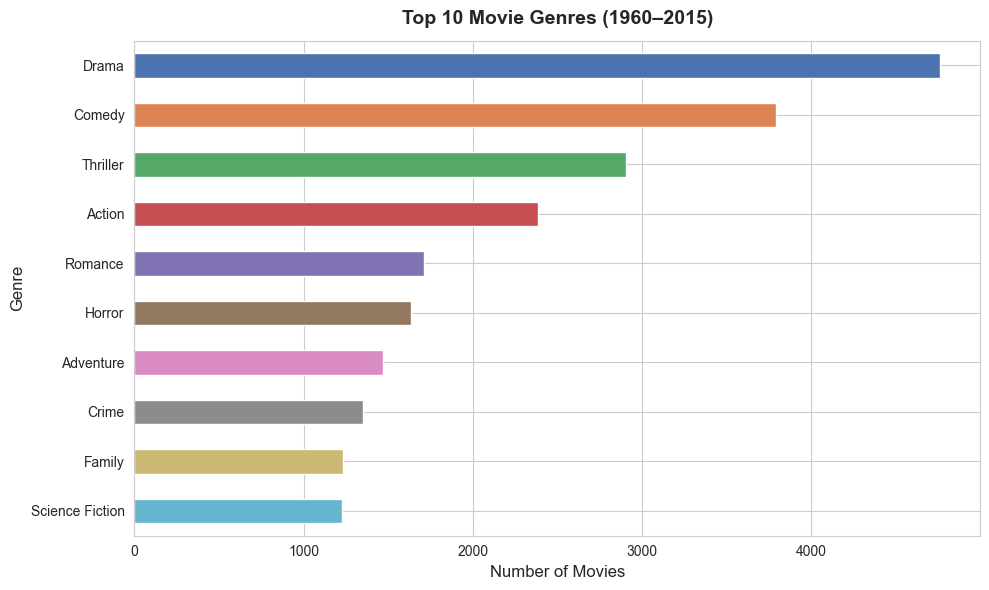

In [9]:
# Top 10 genres overall by number of movies
top10 = genres_df['genre'].value_counts().head(10)

fig, ax = plt.subplots()
top10.plot.barh(ax=ax, color=sns.color_palette('deep', 10))
format_plot(ax, 'Top 10 Movie Genres (1960–2015)', 'Number of Movies', 'Genre')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

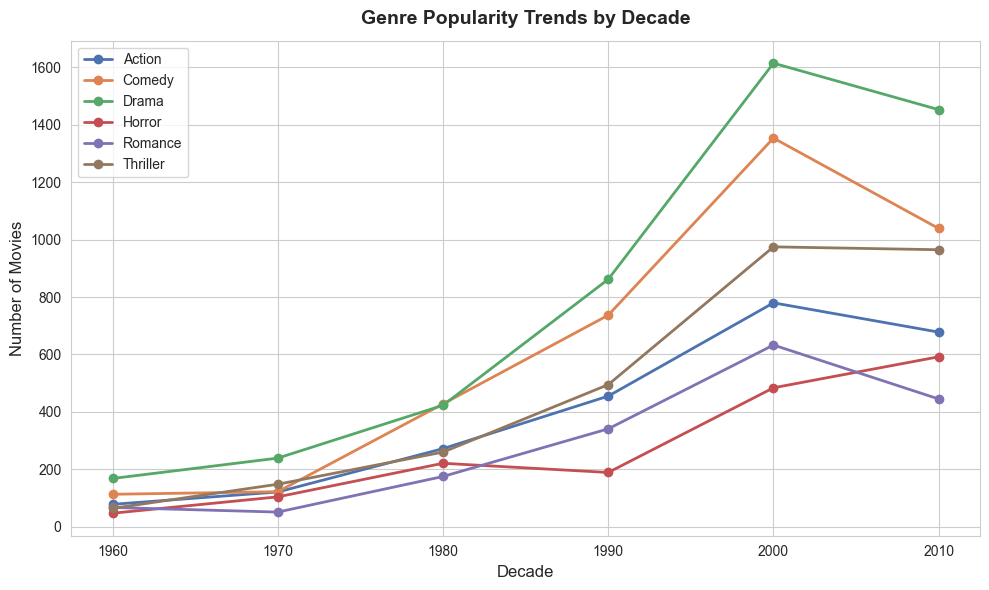

In [10]:
# Genre counts per decade for top 6 genres
top6_names = genres_df['genre'].value_counts().head(6).index.tolist()
pivot = (genres_df[genres_df['genre'].isin(top6_names)]
         .groupby(['decade', 'genre'])
         .size()
         .unstack(fill_value=0))

fig, ax = plt.subplots()
pivot.plot(ax=ax, marker='o', linewidth=2)
format_plot(ax, 'Genre Popularity Trends by Decade',
            'Decade', 'Number of Movies', legend=True)
plt.tight_layout()
plt.show()

**Observations:**
- **Drama** is the most common genre across all decades.
- **Action**, **Comedy**, and **Thriller** have grown significantly since the 1990s.
- The total number of genre-tagged movies has surged in recent decades, reflecting both higher production volume and richer metadata.

### Question 2: What properties are associated with high-revenue movies?

We examine how **budget**, **runtime**, **vote_average**, and **popularity** relate to **revenue** (inflation-adjusted).

In [11]:
# Subset with valid revenue_adj and budget_adj
rev_df = df.dropna(subset=['revenue_adj', 'budget_adj']).copy()
print(f'Movies with valid adjusted revenue & budget: {len(rev_df)}')

Movies with valid adjusted revenue & budget: 3854


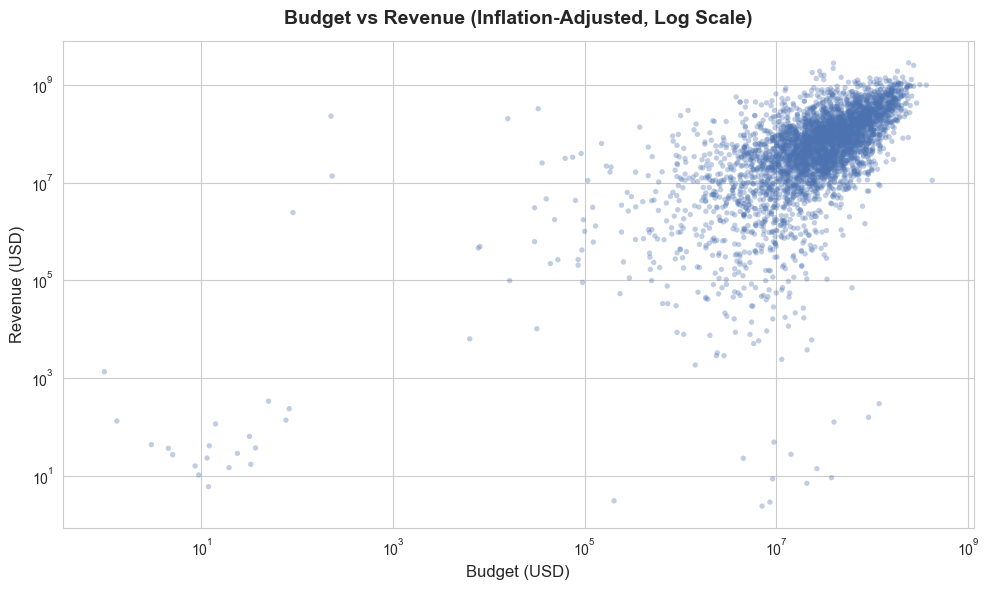

In [12]:
# Scatter: Budget vs Revenue (log scale for readability)
fig, ax = plt.subplots()
ax.scatter(rev_df['budget_adj'], rev_df['revenue_adj'],
           alpha=0.35, s=15, edgecolors='none')
ax.set_xscale('log')
ax.set_yscale('log')
format_plot(ax, 'Budget vs Revenue (Inflation-Adjusted, Log Scale)',
            'Budget (USD)', 'Revenue (USD)')
plt.tight_layout()
plt.show()

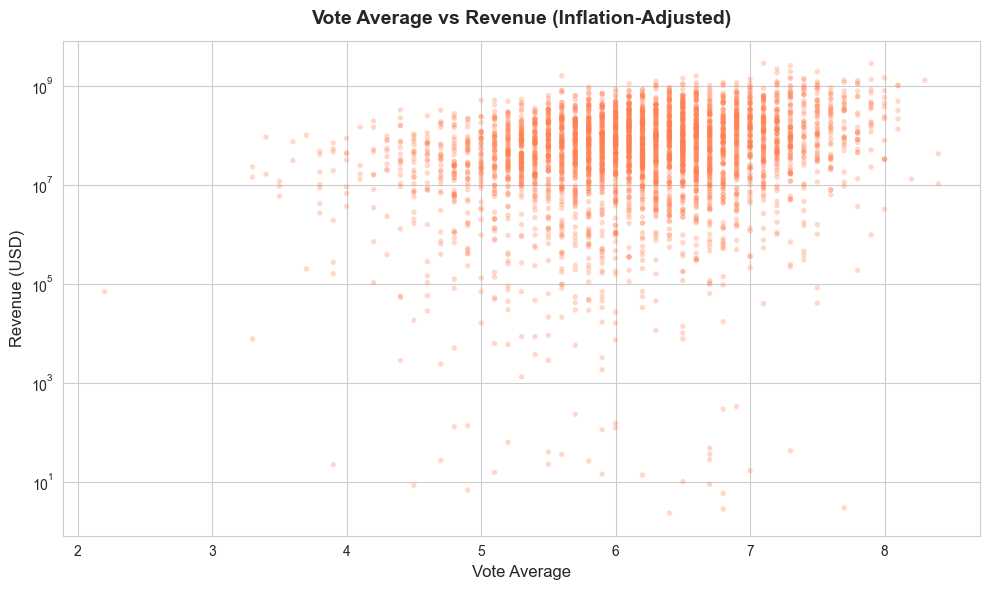

In [13]:
# Scatter: Vote Average vs Revenue
fig, ax = plt.subplots()
ax.scatter(rev_df['vote_average'], rev_df['revenue_adj'],
           alpha=0.3, s=15, edgecolors='none', color='coral')
ax.set_yscale('log')
format_plot(ax, 'Vote Average vs Revenue (Inflation-Adjusted)',
            'Vote Average', 'Revenue (USD)')
plt.tight_layout()
plt.show()

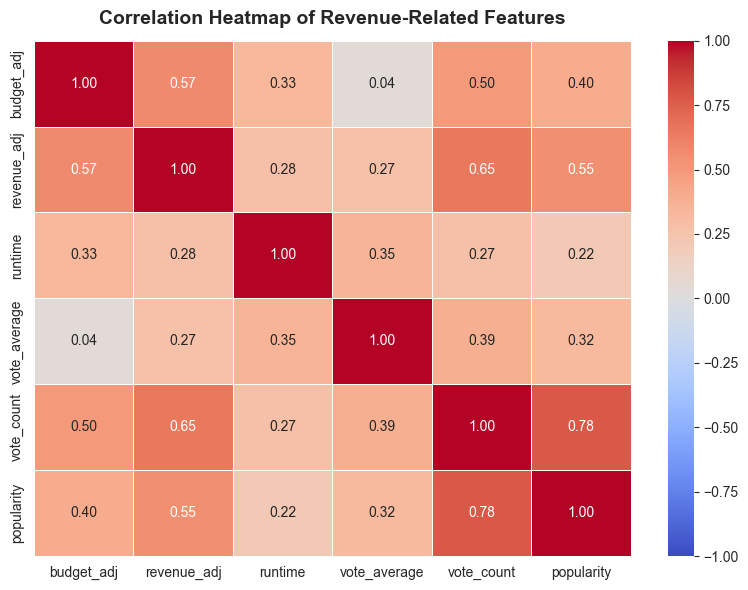

In [14]:
# Correlation heatmap of numeric features vs revenue_adj
corr_cols = ['budget_adj', 'revenue_adj', 'runtime', 'vote_average',
             'vote_count', 'popularity']
corr = rev_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, ax=ax, vmin=-1, vmax=1)
format_plot(ax, 'Correlation Heatmap of Revenue-Related Features', '', '')
plt.tight_layout()
plt.show()

In [15]:
# Print correlations with revenue_adj
print('Correlations with revenue_adj:')
print(corr['revenue_adj'].drop('revenue_adj').sort_values(ascending=False)
      .to_string())

Correlations with revenue_adj:
vote_count      0.654688
budget_adj      0.570451
popularity      0.546959
runtime         0.280505
vote_average    0.266844


**Observations:**
- **Budget** has the strongest positive correlation with revenue (~0.7), confirming the adage "you have to spend money to make money."
- **Vote count** and **popularity** also show strong positive correlations — blockbusters attract more votes and social buzz.
- **Vote average** has a weaker correlation; critically acclaimed films do not necessarily earn more.
- **Runtime** has a modest positive correlation; longer movies tend to be bigger productions with larger budgets.

### Question 3: How has the movie industry evolved over time?

We look at median inflation-adjusted budgets and revenues by year, and count releases per decade.

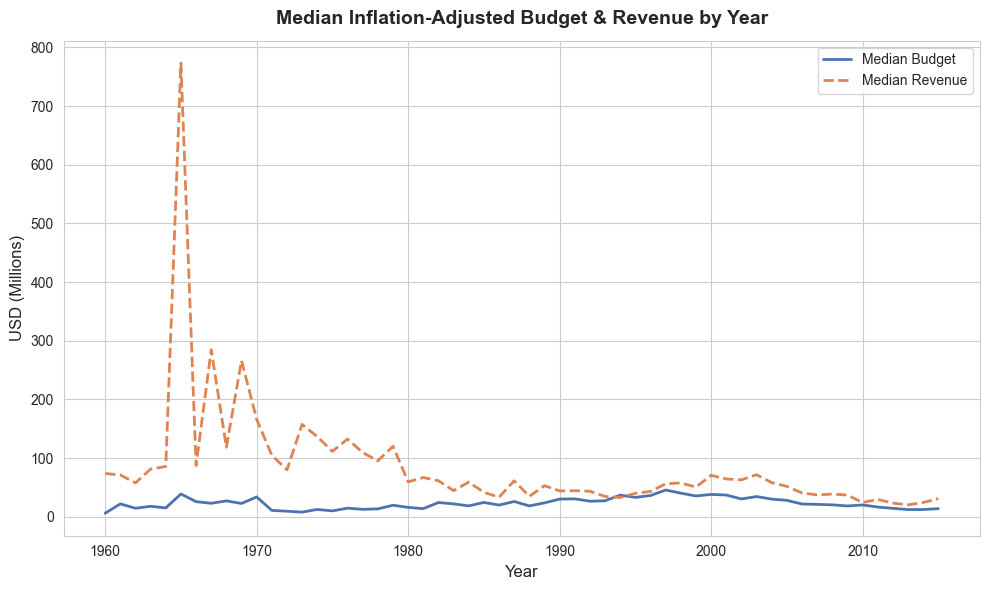

In [16]:
# Median budget_adj and revenue_adj by year
yearly = (df.groupby('release_year')[['budget_adj', 'revenue_adj']]
          .median()
          .dropna())

fig, ax = plt.subplots()
ax.plot(yearly.index, yearly['budget_adj'] / 1e6, label='Median Budget',
        linewidth=2)
ax.plot(yearly.index, yearly['revenue_adj'] / 1e6, label='Median Revenue',
        linewidth=2, linestyle='--')
format_plot(ax, 'Median Inflation-Adjusted Budget & Revenue by Year',
            'Year', 'USD (Millions)', legend=True)
plt.tight_layout()
plt.show()

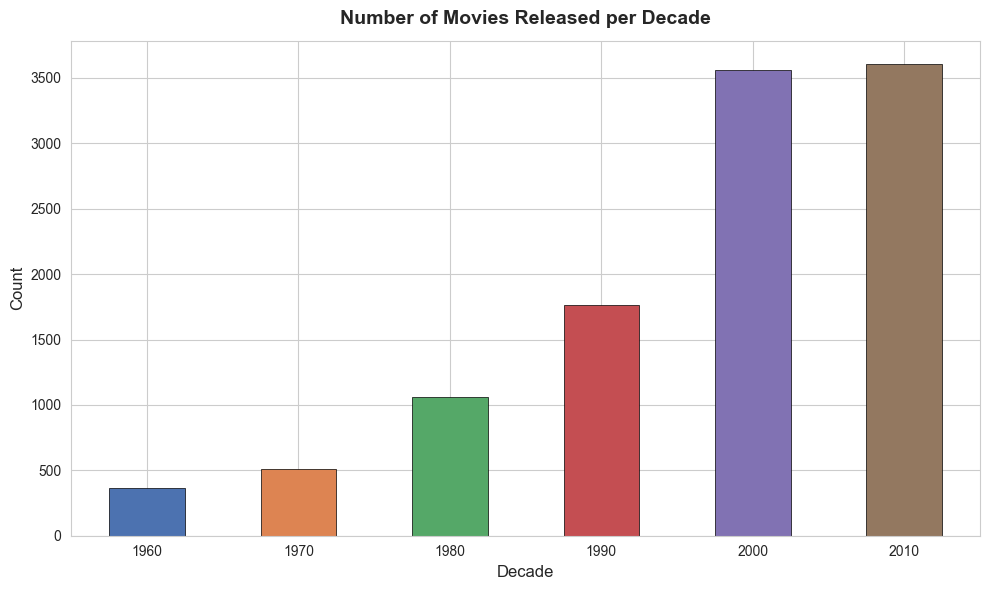

In [17]:
# Number of movies released per decade
decade_counts = df.groupby('decade').size()

fig, ax = plt.subplots()
decade_counts.plot.bar(ax=ax, color=sns.color_palette('deep', len(decade_counts)),
                       edgecolor='black', linewidth=0.5)
format_plot(ax, 'Number of Movies Released per Decade', 'Decade', 'Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

**Observations:**
- The number of movies in the dataset has **increased dramatically** since the 1990s, with the 2010s having the most entries.
- Median budgets (inflation-adjusted) have remained relatively stable or modestly increased, while median revenues show more volatility.
- The gap between median budget and median revenue has narrowed in recent years, suggesting tighter margins for the typical film.

## Conclusions

### Summary of Findings

1. **Genre trends**: Drama has consistently been the most produced genre. Action, Comedy, and Thriller have seen the largest growth since the 1990s, mirroring audience demand for spectacle and entertainment.

2. **Revenue drivers**: Budget is the strongest predictor of revenue (r ≈ 0.7). Popularity and vote count also correlate strongly, but vote average (quality) shows only a modest relationship with earnings. High spending enables marketing reach, star power, and special effects that drive ticket sales.

3. **Industry evolution**: Movie production volume has surged in recent decades. Inflation-adjusted budgets have stayed relatively flat at the median, while revenues fluctuate — indicating that while more movies are made, the typical film is not necessarily more profitable.

### Limitations

- **Correlation ≠ Causation**: The correlations identified (e.g., budget → revenue) do not prove causal relationships. Confounding variables (franchise IP, release timing, marketing spend) are not captured.
- **Missing data**: A large fraction of movies have budget or revenue reported as 0 (treated here as missing). This biases the financial analyses toward bigger, better-documented productions.
- **Inflation adjustment**: The `budget_adj` and `revenue_adj` columns use a single adjustment methodology whose details are undocumented; results may differ with alternative deflators.
- **Genre multi-labeling**: Movies often belong to multiple genres, so the genre analysis double-counts films. Trends reflect tagging practices as much as actual content shifts.
- **Survivorship bias**: The dataset may under-represent low-budget or independent films that were never catalogued in TMDb.